In [3]:
import pandas as pd
import nltk
import matplotlib.pyplot as plt
df=pd.read_csv('/content/sentiments.csv',encoding='ISO-8859-1',names=['Text','Emotions'],sep=';')
df

,Text,Emotions
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


In [4]:
#DATA UNDERSTANDING

#first 3 rows
print(df.head(3))

                                                Text Emotions
0                            i didnt feel humiliated  sadness
1  i can go from feeling so hopeless to so damned...  sadness
2   im grabbing a minute to post i feel greedy wrong    anger


In [5]:
#last 3 rows
print(df.tail(3))

                                                    Text Emotions
15997                     i feel strong and good overall      joy
15998  i feel like this was such a rude comment and i...    anger
15999  i know a lot but i feel so stupid because i ca...  sadness


In [6]:
#number of rows and column
print(df.shape)
#dimension
print(df.ndim)

(16000, 2)
2


In [7]:
#statistical summary
print(df.describe())

                                                     Text Emotions
count                                               16000    16000
unique                                              15969        6
top     im still not sure why reilly feels the need to...      joy
freq                                                    2     5362


In [8]:
#informations
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Text      16000 non-null  object
 1   Emotions  16000 non-null  object
dtypes: object(2)
memory usage: 250.1+ KB
None


In [9]:
#number of unique values
print(df.nunique())

Text        15969
Emotions        6
dtype: int64


In [10]:
#datatypes
print(df.dtypes)

Text        object
Emotions    object
dtype: object


In [11]:
#column names
print(df.columns)

Index(['Text', 'Emotions'], dtype='object')


In [12]:
#duplicates
print(df.duplicated().sum())

1


In [13]:
#null values
print(df.isnull().sum())

Text        0
Emotions    0
dtype: int64


In [14]:
#DATA CLEANING

#drop duplicates
df=df.drop_duplicates()
print(df.shape)

(15999, 2)


Emotions
joy         5361
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64


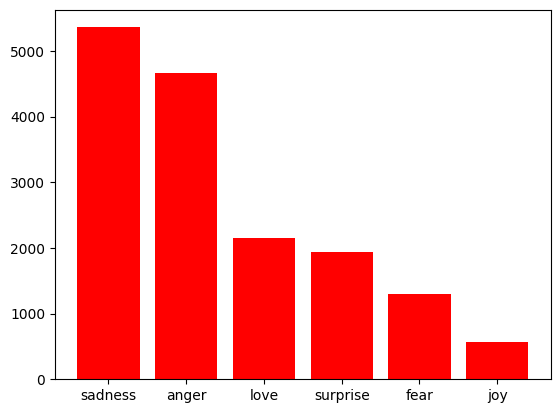

In [15]:
#target column
print(df['Emotions'].value_counts())
xlab=df['Emotions'].unique()
ylab=df['Emotions'].value_counts()
plt.bar(xlab,ylab,color='red')
plt.show()

In [16]:
#label encoding for target column
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['Emotions']=le.fit_transform(df['Emotions'])
df

/tmp/ipykernel_420/850895164.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Emotions']=le.fit_transform(df['Emotions'])


,Text,Emotions
0,i didnt feel humiliated,4
1,i can go from feeling so hopeless to so damned...,4
2,im grabbing a minute to post i feel greedy wrong,0
3,i am ever feeling nostalgic about the fireplac...,3
4,i am feeling grouchy,0
...,...,...
15995,i just had a very brief time in the beanbag an...,4
15996,i am now turning and i feel pathetic that i am...,4
15997,i feel strong and good overall,2
15998,i feel like this was such a rude comment and i...,0


In [17]:
#defining text column to a variable
obj=df['Text']
obj

,Text
0,i didnt feel humiliated
1,i can go from feeling so hopeless to so damned...
2,im grabbing a minute to post i feel greedy wrong
3,i am ever feeling nostalgic about the fireplac...
4,i am feeling grouchy
...,...
15995,i just had a very brief time in the beanbag an...
15996,i am now turning and i feel pathetic that i am...
15997,i feel strong and good overall
15998,i feel like this was such a rude comment and i...


In [18]:
#TOKENIZATION
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
obj=obj.apply(lambda x:" ".join(word_tokenize(x)))
obj

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


,Text
0,i didnt feel humiliated
1,i can go from feeling so hopeless to so damned...
2,im grabbing a minute to post i feel greedy wrong
3,i am ever feeling nostalgic about the fireplac...
4,i am feeling grouchy
...,...
15995,i just had a very brief time in the beanbag an...
15996,i am now turning and i feel pathetic that i am...
15997,i feel strong and good overall
15998,i feel like this was such a rude comment and i...


In [19]:
#SPECIAL CHARACTER REMOVAL
obj=obj.replace('[^a-zA-Z0-9]',' ',regex=True)
obj

,Text
0,i didnt feel humiliated
1,i can go from feeling so hopeless to so damned...
2,im grabbing a minute to post i feel greedy wrong
3,i am ever feeling nostalgic about the fireplac...
4,i am feeling grouchy
...,...
15995,i just had a very brief time in the beanbag an...
15996,i am now turning and i feel pathetic that i am...
15997,i feel strong and good overall
15998,i feel like this was such a rude comment and i...


In [20]:
#REMOVING WORD WITH LESS THAN 3 LETTERS
obj=obj.apply(lambda x:" ".join([i for i in word_tokenize(x) if len(i)>=3]))
obj

,Text
0,didnt feel humiliated
1,can from feeling hopeless damned hopeful just ...
2,grabbing minute post feel greedy wrong
3,ever feeling nostalgic about the fireplace wil...
4,feeling grouchy
...,...
15995,just had very brief time the beanbag and said ...
15996,now turning and feel pathetic that still waiti...
15997,feel strong and good overall
15998,feel like this was such rude comment and glad ...


In [21]:
#STEMMING AND REMOVING STOP WORDS
nltk.download('stopwords')
from nltk.stem import SnowballStemmer
from nltk.corpus import stopwords
st=stopwords.words('english')
ss=SnowballStemmer('english')
obj=obj.apply(lambda x:" ".join([ss.stem(i.lower()) for i in word_tokenize(x) if i.lower() not in st]))
obj

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,Text
0,didnt feel humili
1,feel hopeless damn hope around someon care awak
2,grab minut post feel greedi wrong
3,ever feel nostalg fireplac know still properti
4,feel grouchi
...,...
15995,brief time beanbag said anna feel like beaten
15996,turn feel pathet still wait tabl sub teach degre
15997,feel strong good overal
15998,feel like rude comment glad


In [22]:
#VECTORIZATION
from sklearn.feature_extraction.text import TfidfVectorizer
vec=TfidfVectorizer()
data=vec.fit_transform(obj)
data

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 140195 stored elements and shape (15999, 10050)>

In [23]:
#input output separation
x=data
y=df['Emotions']
x

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 140195 stored elements and shape (15999, 10050)>

In [24]:
#TRAIN TEST SPLITTING
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.30,random_state=41)
print(xtrain.shape)
print(ytrain.shape)
print(xtest.shape)
print(ytest.shape)

(11199, 10050)
(11199,)
(4800, 10050)
(4800,)


In [26]:
#DATA BALANCING
print(ytrain.value_counts())
from imblearn.over_sampling import SMOTE
sm=SMOTE()
xtrain1,ytrain1=sm.fit_resample(xtrain,ytrain)
print(ytrain1.value_counts())

Emotions
2    3755
4    3254
0    1513
1    1347
3     938
5     392
Name: count, dtype: int64
Emotions
2    3755
1    3755
4    3755
0    3755
3    3755
5    3755
Name: count, dtype: int64


In [27]:
from sklearn.model_selection import GridSearchCV
#HYPERPARAMETER TUNING OF KNN MODEL
from sklearn.neighbors import KNeighborsClassifier
knn_model=KNeighborsClassifier()
knn_param={'n_neighbors':[5,7,9,11],'weights':['distance','random'],'metric':['euclidean','manhattan']}
knn_grid=GridSearchCV(knn_model,knn_param,cv=3,scoring='accuracy')
knn_grid.fit(xtrain1,ytrain1)
knn_grid.best_params_

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
24 fits failed out of a total of 48.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
24 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_par

{'metric': 'euclidean', 'n_neighbors': 5, 'weights': 'distance'}

In [28]:
#MODEL BUILDING-KNN
knn=KNeighborsClassifier(n_neighbors=5,weights='distance',metric='euclidean')
knn.fit(xtrain1,ytrain1)
knn_ypred=knn.predict(xtest)
knn_ypred

array([3, 3, 3, ..., 0, 3, 4])

In [29]:
#HYPERPARAMETER TUNING OF NB MODEL
from sklearn.naive_bayes import BernoulliNB
nb_model=BernoulliNB()
nb_param={'alpha':[0.1,0.5,1.0,5.0,10.0],'binarize':[0.0,0.5,1.0],'fit_prior':[True,False]}
nb_grid=GridSearchCV(nb_model,nb_param,cv=3,scoring='accuracy')
nb_grid.fit(xtrain1,ytrain1)
nb_grid.best_params_

{'alpha': 0.5, 'binarize': 0.0, 'fit_prior': True}

In [30]:
#NB MODEL BUILDING
nb=BernoulliNB(alpha=0.5, binarize=0.0, fit_prior=True)
nb.fit(xtrain1,ytrain1)
nb_ypred=nb.predict(xtest)
nb_ypred

array([2, 3, 4, ..., 2, 3, 2])

In [31]:
#HYPERPARAMETER TUNING OF DT MODEL
from sklearn.tree import DecisionTreeClassifier
dt_model=DecisionTreeClassifier(random_state=41)
dt_params={'criterion':['gini','entropy','log_loss'],'max_depth':[3,5,7,10,None],'min_samples_split':[2,5,10],
           'min_samples_leaf':[1,2,4]}
dt_grid=GridSearchCV(dt_model,dt_params,cv=3,scoring='accuracy')
dt_grid.fit(xtrain1,ytrain1)
dt_grid.best_params_

{'criterion': 'gini',
 'max_depth': None,
 'min_samples_leaf': 1,
 'min_samples_split': 4}

In [32]:
#DT MODEL BUILDING
dt=DecisionTreeClassifier(criterion='gini',max_depth=None,min_samples_split=4,min_samples_leaf=1,random_state=41)
dt.fit(xtrain1,ytrain1)
dt_ypred=dt.predict(xtest)
dt_ypred

array([4, 2, 4, ..., 4, 3, 2])

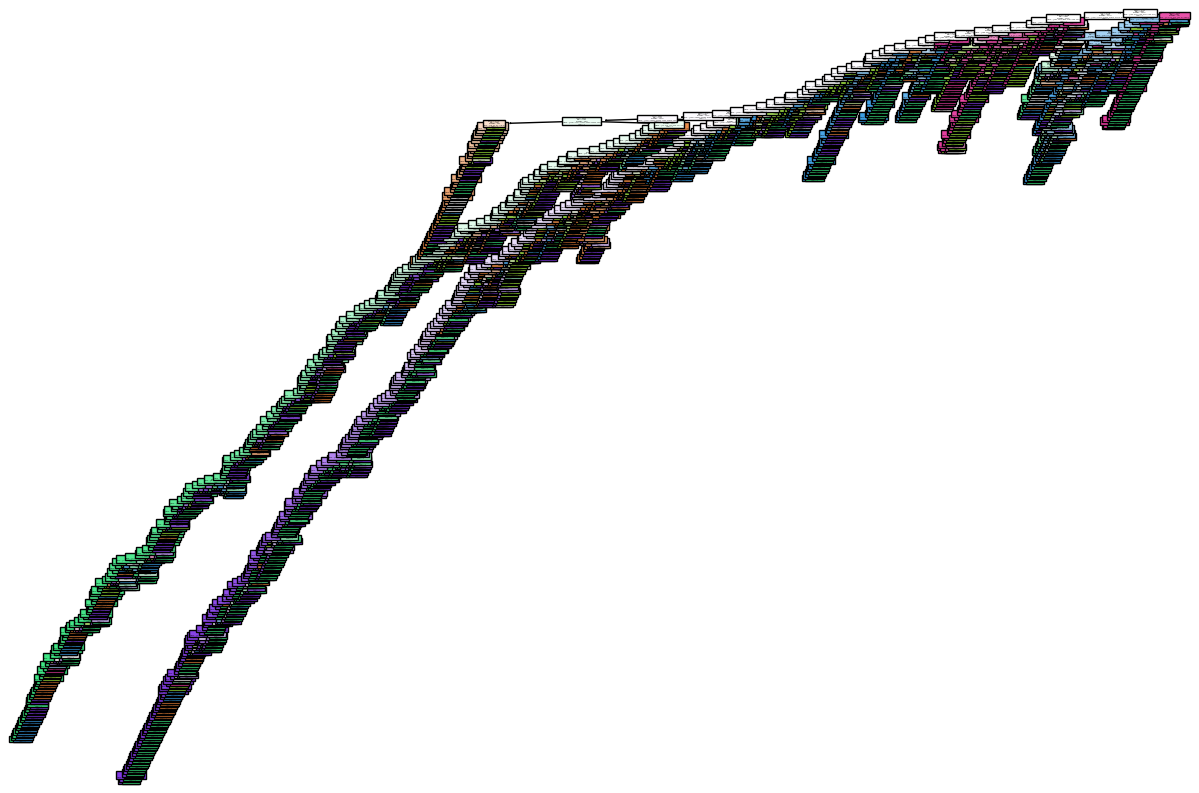

In [36]:
#TREE VISUALIZATION
from sklearn import tree
plt.figure(figsize=(15,10))
tree.plot_tree(dt,feature_names=vec.get_feature_names_out(),class_names=df['Emotions'].astype(str).unique(),filled=True)
plt.show()

In [ ]:
#HYPERPARAMETER TUNING OF RFC MODEL
from sklearn.ensemble import RandomForestClassifier
rfc_model=RandomForestClassifier(random_state=41)
rfc_param={'n_estimators':[60,90,120],'max_depth':[10,15,20,None],'min_samples_split':[2,5,10],'min_samples_leaf':[1,2,4]}
rfc_grid=GridSearchCV(rfc_model,rfc_param,cv=3,scoring='accuracy')
rfc_grid.fit(xtrain1,ytrain1)
rfc.grid_best_params_

NameError: name 'rfc' is not defined

In [24]:
#RFC MODEL BUILDING
rfc=RandomForestClassifier(n_estimators=,max_depth=,min_samples_split=,min_samples_leaf=,random_state=41)
rfc.fit(xtrain1,ytrain1)
rfc_ypred=rfc.predict(xtest)
rfc_ypred

In [24]:
#HYPERPARAMETER TUNING OF XGB MODEL
from xgboost import XGBClassifier
xgb_model=XGBClassifier(random_state=41)
xgb_param={'n_estimators':[60,90,120],'max_depth':[10,15,20,None],'learning_rate':[0.01,0.1],'subsample':[0.8,1.0]}
xgb_grid=GridSearchCV(xgb_model,xgb_param,cv=3,scoring='accuracy')
xgb_grid.fit(xtrain1,ytrain1)
xgb_grid.best_params_

In [24]:
#XGB MODEL BUILDING
xgb=XGBClassifier(n_estimators=,max_depth=,learning_rate=,subsample=,random_state=41)
xgb.fit(xtrain1,ytrain1)
xgb_ypred=xgb.predict(xtest)
xgb_ypred

In [24]:
#HYPERPARAMETER TUNING OF LR MODEL
from sklearn.linear_model import LogisticRegression
lr_model=LogisticRegression()
lr_param={'C':[0.01,0.1,1,10,100],'penalty':['l2','l2'],'solver':['liblinear']}
lr_grid=GridSearchCV(lr_model,lr_param,cv=3,scoring='accuracy')
lr_grid.fit(xtrain1,ytrain1)
lr_grid.best_params_

In [24]:
#LR MODEL BUILDING
lr=LogisticRegression(C=,penalty='l1',solver='linlinear')
lr.fit(xtrain1,ytrain1)
lr_ypred=lr.predict(xtest)
lr_ypred

In [24]:
ytest.values

In [24]:
#TRAINING AND TESTING SCORE
print("KNN  Training Score:",knn.score(xtrain1,ytrain1),  "Testing score:",knn.score(xtest,ytest))
print("NB Training Score:",nb.score(xtrain1,ytrain1), "Testing score:",nb.score(xtest,ytest))
print("DT Training Score:",dt.score(xtrain1,ytrain1), "Testing score:",dt.score(xtest,ytest))
print("RFC  Training Score:",rfc.score(xtrain1,ytrain1),  "Testing score:",rfc.score(xtest,ytest))
print("XGB Training Score:",xgb.score(xtrain1,ytrain1), "Testing score:",xgb.score(xtest,ytest))
print("LR Training Score:",lr.score(xtrain1,ytrain1), "Testing score:",lr.score(xtest,ytest))

In [ ]:
#